In [1]:
import glob
import os
import numpy as np
import shutil
import matplotlib.pyplot as plt
import h5py
import time
import random
import torch
import torch.multiprocessing
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import random_split, Dataset, DataLoader, ConcatDataset
import torchvision
from torchvision.io import read_image
import torchvision.transforms as transforms
from torchvision.models import resnet34
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, classification_report 
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_curve, auc

from PIL import Image
mps_device = torch.device("mps")

In [ ]:
files = glob.glob('images'+'/**/*.JPG', recursive=True)

for file in files:
    if 'Ethanol' in file:
        name = file.split('/')[1]
        try:
            shutil.copy(file, 'data/ethanol/'+name)
            print(f"File '{os.path.basename(file)}' moved successfully to '/data/ethanol/")
        except FileNotFoundError:
            print(f"Error: File '{file}' not found.")
        except Exception as e:
            print(f"An error occurred: {e}")
    if 'Pentane' in file:
        name = file.split('/')[1]
        try:
            shutil.copy(file, 'data/pentane/'+name)
            print(f"File '{os.path.basename(file)}' moved successfully to '/data/ethanol/")
        except FileNotFoundError:
            print(f"Error: File '{file}' not found.")
        except Exception as e:
            print(f"An error occurred: {e}")
    if 'Propanol' in file:
        name = file.split('/')[1]
        try:
            shutil.copy(file, 'data/propanol/'+name)
            print(f"File '{os.path.basename(file)}' moved successfully to '/data/ethanol/")
        except FileNotFoundError:
            print(f"Error: File '{file}' not found.")
        except Exception as e:
            print(f"An error occurred: {e}")

In [3]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.RandomApply(torch.nn.ModuleList([transforms.ColorJitter(brightness=0, contrast=0, saturation=0, hue=0), ]), p=0.3),
    transforms.Resize((224, 224), antialias=True),  
    transforms.ToTensor()
])
data = torchvision.datasets.ImageFolder('data/', transform=transform)
train, val, test = random_split(data, [0.8, 0.1, 0.1])
train_loader = torch.utils.data.DataLoader(train, batch_size=100, shuffle=True)
train_val_loader = torch.utils.data.DataLoader(ConcatDataset([train, val]), batch_size=100, shuffle=True)
val_loader = torch.utils.data.DataLoader(val, batch_size=300, shuffle=True)
test_loader = torch.utils.data.DataLoader(test, batch_size=300, shuffle=True)

In [4]:
num_classes = 3
model = resnet34(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model.to(mps_device)

loss_func = nn.CrossEntropyLoss()
opt = optim.Adam(model.parameters(), lr=1e-04, weight_decay=1e-5)

model.eval()
with torch.no_grad():
    torch.mps.empty_cache()
    for x, y in test_loader:
        # Forward Pass Train
        input = x.to(mps_device)
        label = y.to(mps_device)
        # Forward Pass Val
        output = model(input)
        y_pred = torch.max(output, 1)[1]
        base_acc = 100 * (y_pred == label).sum().item() / len(label)
        print(f'Baseline Model Accuracy:{base_acc} %')
model.train()

/Users/robin/miniconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Baseline Model Accuracy:37.0 %


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [5]:
train_losses, train_accs = [], []
val_losses, val_accs = [], []

model.eval()

with torch.no_grad():
    for x, y in train_loader:
        # Forward Pass Train
        input = x.to(mps_device)
        label = y.to(mps_device)
        
        # Forward Pass
        output = model(input)
        y_pred = torch.max(output, 1)[1]
        
        train_loss = loss_func(output, label).item()
        train_acc = 100 * (y_pred == label).sum().item() / len(label)

        break
        
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    for x, y in val_loader:
        # Forward Pass Train
        input = x.to(mps_device)
        label = y.to(mps_device)
    
        # Forward Pass Val
        output = model(input)
        y_pred = torch.max(output, 1)[1]
        
        val_loss = loss_func(output, label).item()
        val_acc = 100 * (y_pred == label).sum().item() / len(label)

    val_losses.append(val_loss)
    val_accs.append(val_acc)

model.train()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [6]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

for epoch in range(20):    
    for x, y in train_loader:
        input = x.to(mps_device)
        label = y.to(mps_device)
        
        # Forward Pass
        output = model(input)

        # Loss + L2 Regularization
        loss = loss_func(output, label) + 1e-4 * sum(torch.pow(p, 2).sum() for p in model.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()

    model.eval()
    with torch.no_grad():
        train_loss = 0
        train_acc = 0
        for x, y in train_loader:
            input = x.to(mps_device)
            label = y.to(mps_device)
            
            # Forward Pass
            output = model(input)
            y_pred = torch.max(output, 1)[1]

            train_loss += loss_func(output, label).item()
            train_acc += 100 * (y_pred == label).sum().item() / len(label)
            
        train_losses.append(train_loss/len(train_loader))
        train_accs.append(train_acc/len(train_loader))
       
        for x, y in val_loader:
            # Forward Pass Train
            input = x.to(mps_device)
            label = y.to(mps_device)
            # Forward Pass Val
            output = model(input)
            y_pred = torch.max(output, 1)[1]
            val_losses.append(loss_func(output, label).item())
            val_accs.append(100 * (y_pred == label).sum().item() / len(label))
    model.train()

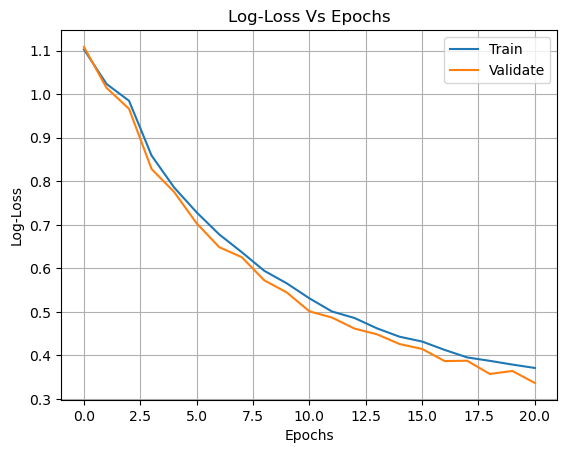

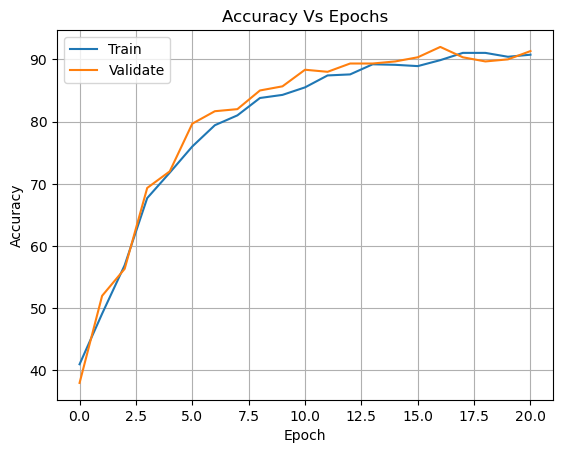

In [7]:
plt.figure()
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validate')
plt.xlabel('Epochs')
plt.ylabel('Log-Loss')
plt.title('Log-Loss Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(train_accs, label='Train')
plt.plot(val_accs, label='Validate')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
opt = optim.Adam(model.parameters(), lr=1e-05, weight_decay=1e-5)

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

for epoch in range(10):    
    for x, y in train_loader:

        if epoch == 8:
            for param in model.conv1.parameters():
                param.requires_grad = True
            
        if epoch == 6:
            for param in model.layer2.parameters():
                param.requires_grad = True

        if epoch == 2:
            for param in model.fc.parameters():
                param.requires_grad = True
        
        input = x.to(mps_device)
        label = y.to(mps_device)
        
        # Forward Pass
        output = model(input)

        # Loss + L2 Regularization
        loss = loss_func(output, label) + 1e-4 * sum(torch.pow(p, 2).sum() for p in model.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()

    model.eval()
    with torch.no_grad():
        train_loss = 0
        train_acc = 0
        for x, y in train_loader:
            input = x.to(mps_device)
            label = y.to(mps_device)
            
            # Forward Pass
            output = model(input)
            y_pred = torch.max(output, 1)[1]

            train_loss += loss_func(output, label).item()
            train_acc += 100 * (y_pred == label).sum().item() / len(label)
            
        train_losses.append(train_loss/len(train_loader))
        train_accs.append(train_acc/len(train_loader))
       
        for x, y in val_loader:
            # Forward Pass Train
            input = x.to(mps_device)
            label = y.to(mps_device)
            # Forward Pass Val
            output = model(input)
            y_pred = torch.max(output, 1)[1]
            val_losses.append(loss_func(output, label).item())
            val_accs.append(100 * (y_pred == label).sum().item() / len(label))
    model.train()

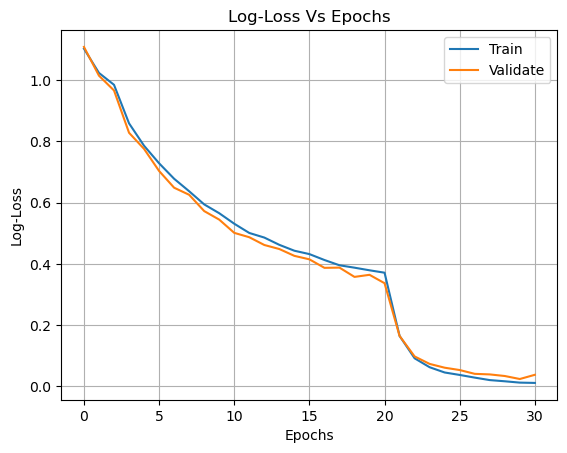

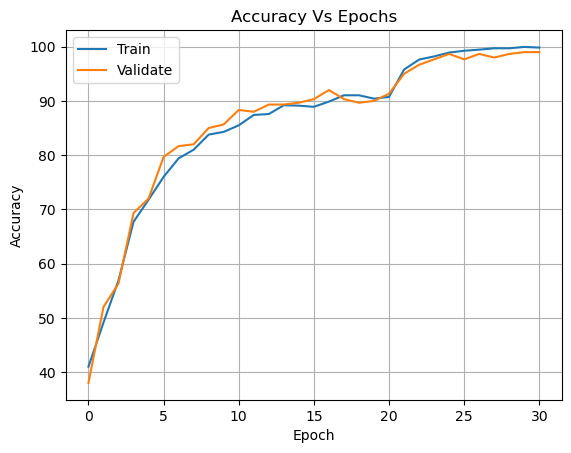

In [9]:
plt.figure()
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validate')
plt.xlabel('Epochs')
plt.ylabel('Log-Loss')
plt.title('Log-Loss Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(train_accs, label='Train')
plt.plot(val_accs, label='Validate')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
input_image = Image.open('data/ethanol/Ethanol_Full_0102.JPG')
t = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),  
    transforms.ToTensor()
])
input_tensor = t(input_image).unsqueeze(0).to(mps_device)

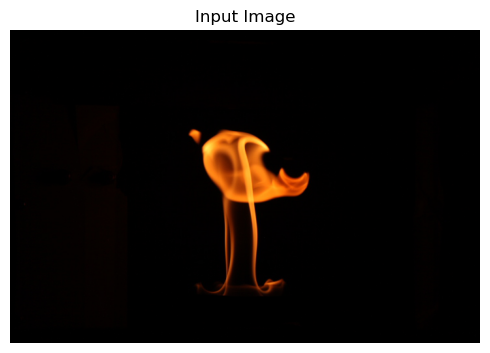

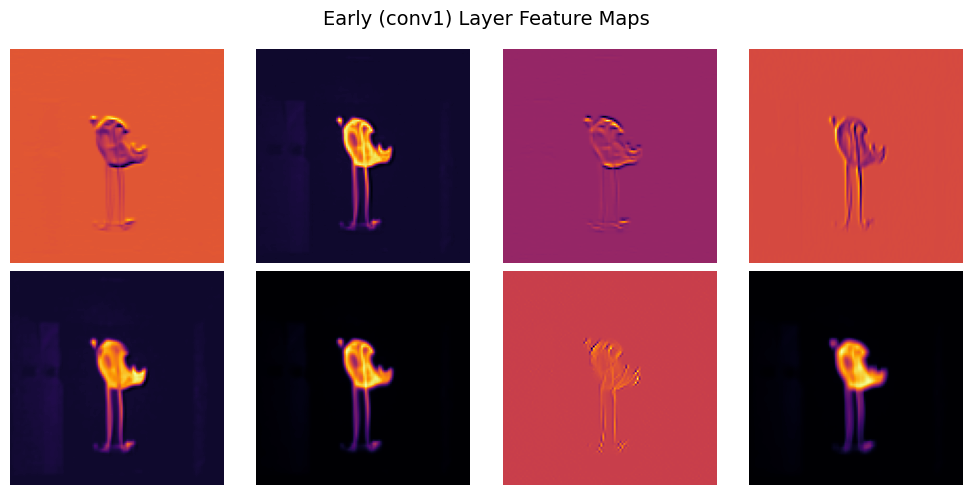

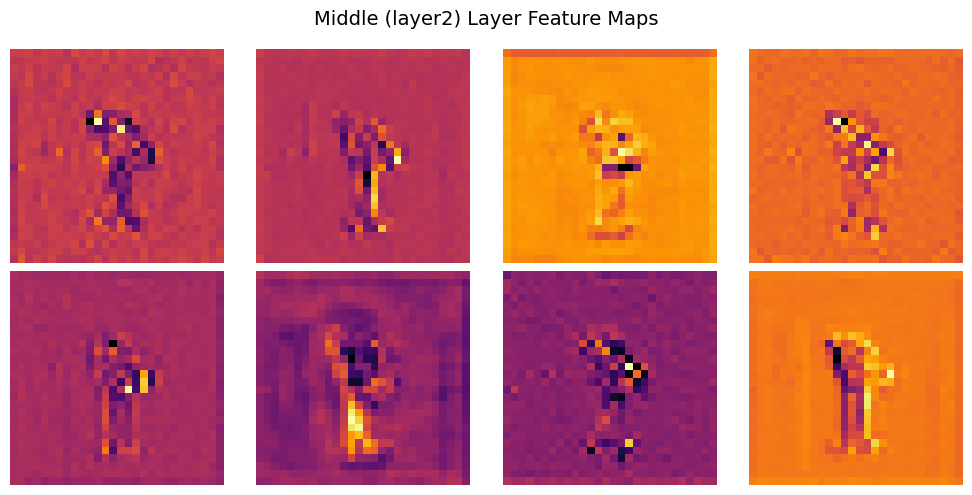

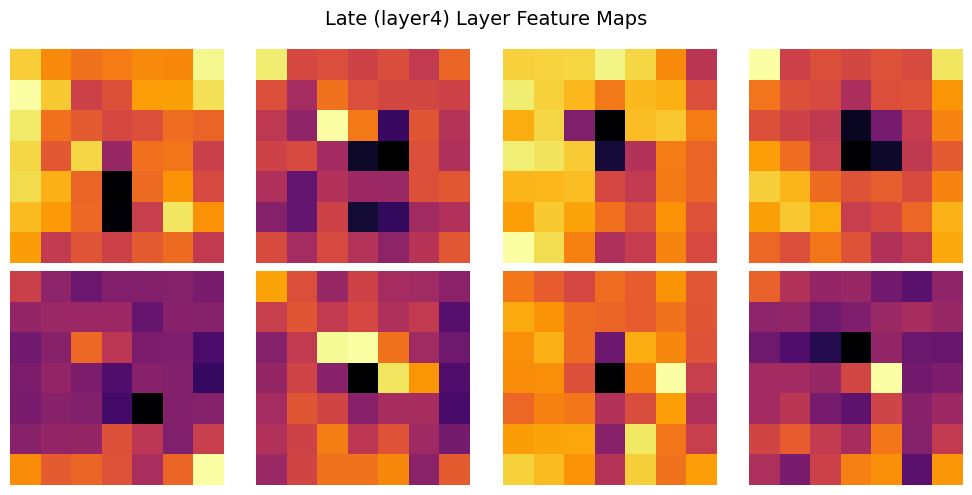

In [11]:
# Register hooks for early and late layers
activations = {}
def hook_fn(name):
    def hook(module, input, output):
        activations[name] = output.detach()
    return hook

# Register hooks to selected layers
early_layer = model.conv1
mid_layer = model.layer2[0].conv1
late_layer = model.layer4[0].conv1

handles = [
    early_layer.register_forward_hook(hook_fn('early')),
    mid_layer.register_forward_hook(hook_fn('mid')),
    late_layer.register_forward_hook(hook_fn('late'))
]

# Forward pass
with torch.no_grad():
    _ = model(input_tensor)  # Fixed the syntax error here

# Remove hooks
for handle in handles:
    handle.remove()

# Function to visualize feature maps with selective display
def visualize_feature_maps(feature_maps, layer_name, num_filters=8):
    # Create a grid of feature maps
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    axes = axes.flatten()
    
    # Use only a subset of channels for clarity
    if feature_maps.shape[1] > num_filters:
        # Select evenly spaced filters
        indices = np.linspace(0, feature_maps.shape[1]-1, num_filters, dtype=int)
        selected_maps = feature_maps[0, indices].cpu().numpy()
    else:
        selected_maps = feature_maps[0, :num_filters].cpu().numpy()
    
    # Plot each feature map
    for i, feature_map in enumerate(selected_maps):
        # Normalize for visualization
        feature_map = (feature_map - feature_map.min()) / (feature_map.max() - feature_map.min() + 1e-8)
        axes[i].imshow(feature_map, cmap='inferno')
        axes[i].axis('off')
    
    plt.suptitle(f"{layer_name} Layer Feature Maps", fontsize=14)
    plt.tight_layout()
    return fig

# Display original input
plt.figure(figsize=(5, 5))
plt.imshow(input_image)
plt.title("Input Image")
plt.axis('off')
plt.tight_layout()
plt.show()

# Visualize early, mid, and late feature maps
early_fig = visualize_feature_maps(activations['early'], "Early (conv1)")
plt.show()

mid_fig = visualize_feature_maps(activations['mid'], "Middle (layer2)")
plt.show()

late_fig = visualize_feature_maps(activations['late'], "Late (layer4)")
plt.show()

In [12]:
input_image = Image.open('data/pentane/Pentane_Full_0765.JPG')
t = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),  
    transforms.ToTensor()
])
input_tensor = t(input_image).unsqueeze(0).to(mps_device)

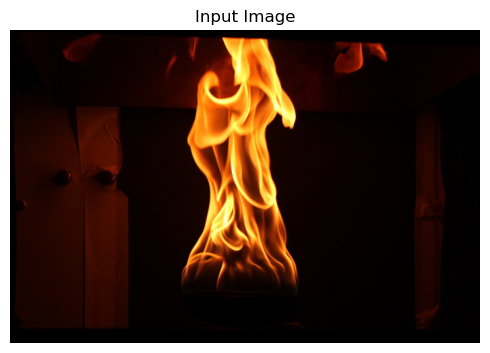

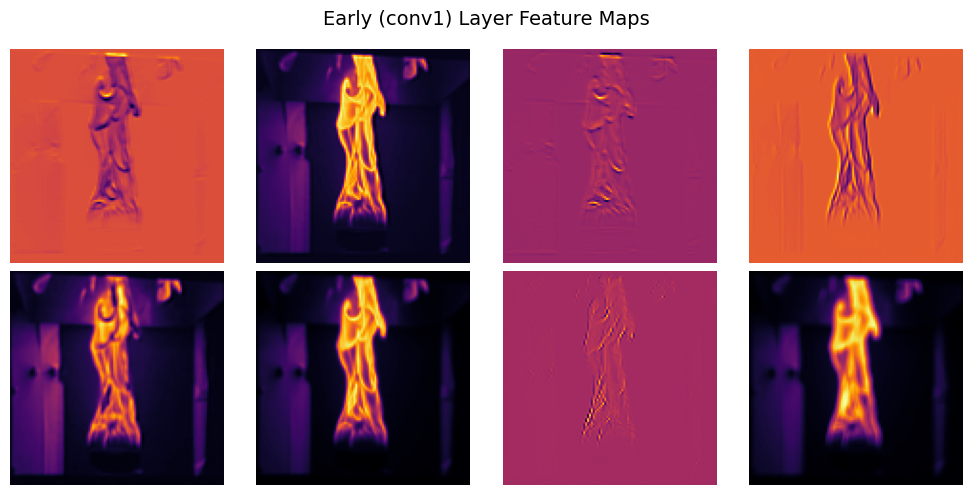

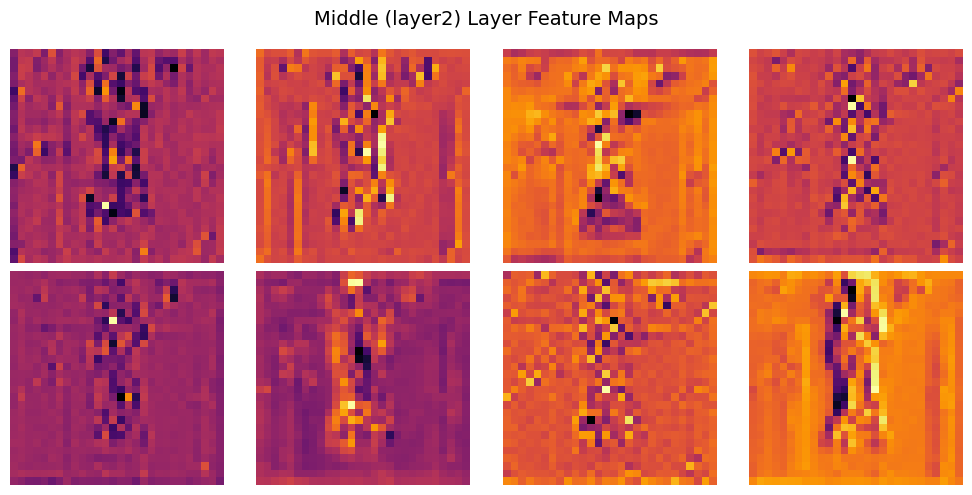

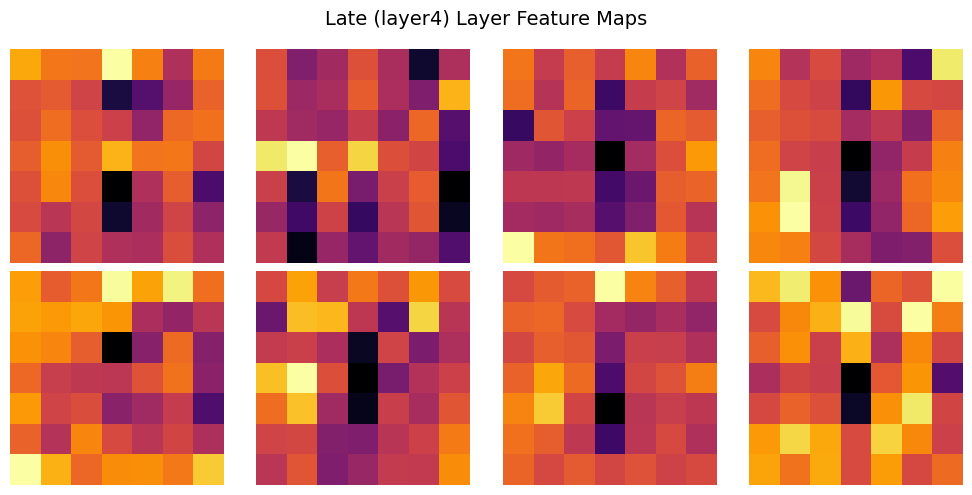

In [13]:
# Register hooks for early and late layers
activations = {}
def hook_fn(name):
    def hook(module, input, output):
        activations[name] = output.detach()
    return hook

# Register hooks to selected layers
early_layer = model.conv1
mid_layer = model.layer2[0].conv1
late_layer = model.layer4[0].conv1

handles = [
    early_layer.register_forward_hook(hook_fn('early')),
    mid_layer.register_forward_hook(hook_fn('mid')),
    late_layer.register_forward_hook(hook_fn('late'))
]

# Forward pass
with torch.no_grad():
    _ = model(input_tensor)  # Fixed the syntax error here

# Remove hooks
for handle in handles:
    handle.remove()

# Function to visualize feature maps with selective display
def visualize_feature_maps(feature_maps, layer_name, num_filters=8):
    # Create a grid of feature maps
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    axes = axes.flatten()
    
    # Use only a subset of channels for clarity
    if feature_maps.shape[1] > num_filters:
        # Select evenly spaced filters
        indices = np.linspace(0, feature_maps.shape[1]-1, num_filters, dtype=int)
        selected_maps = feature_maps[0, indices].cpu().numpy()
    else:
        selected_maps = feature_maps[0, :num_filters].cpu().numpy()
    
    # Plot each feature map
    for i, feature_map in enumerate(selected_maps):
        # Normalize for visualization
        feature_map = (feature_map - feature_map.min()) / (feature_map.max() - feature_map.min() + 1e-8)
        axes[i].imshow(feature_map, cmap='inferno')
        axes[i].axis('off')
    
    plt.suptitle(f"{layer_name} Layer Feature Maps", fontsize=14)
    plt.tight_layout()
    return fig

# Display original input
plt.figure(figsize=(5, 5))
plt.imshow(input_image)
plt.title("Input Image")
plt.axis('off')
plt.tight_layout()
plt.show()

# Visualize early, mid, and late feature maps
early_fig = visualize_feature_maps(activations['early'], "Early (conv1)")
plt.show()

mid_fig = visualize_feature_maps(activations['mid'], "Middle (layer2)")
plt.show()

late_fig = visualize_feature_maps(activations['late'], "Late (layer4)")
plt.show()

In [14]:
input_image = Image.open('data/propanol/Propanol_Ful_0292.JPG')
t = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),  
    transforms.ToTensor()
])
input_tensor = t(input_image).unsqueeze(0).to(mps_device)

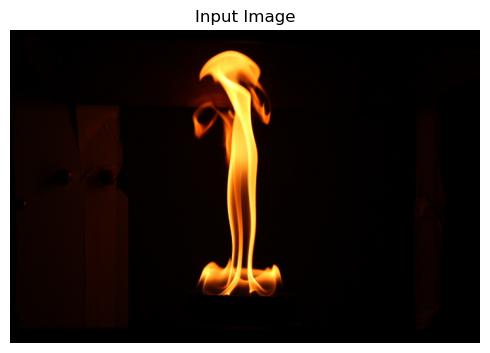

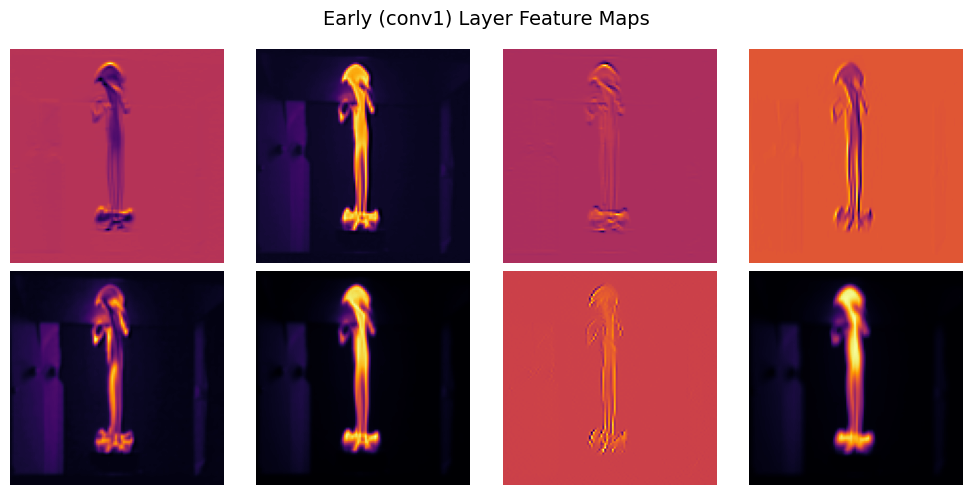

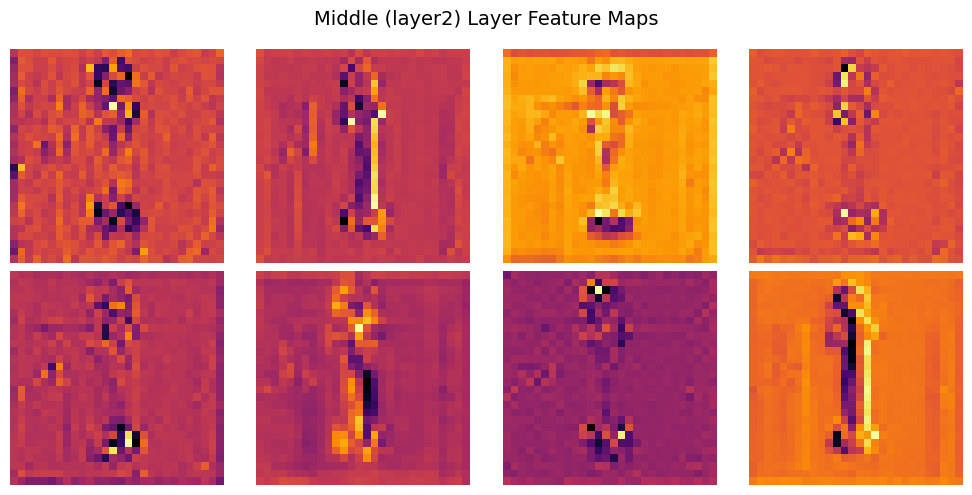

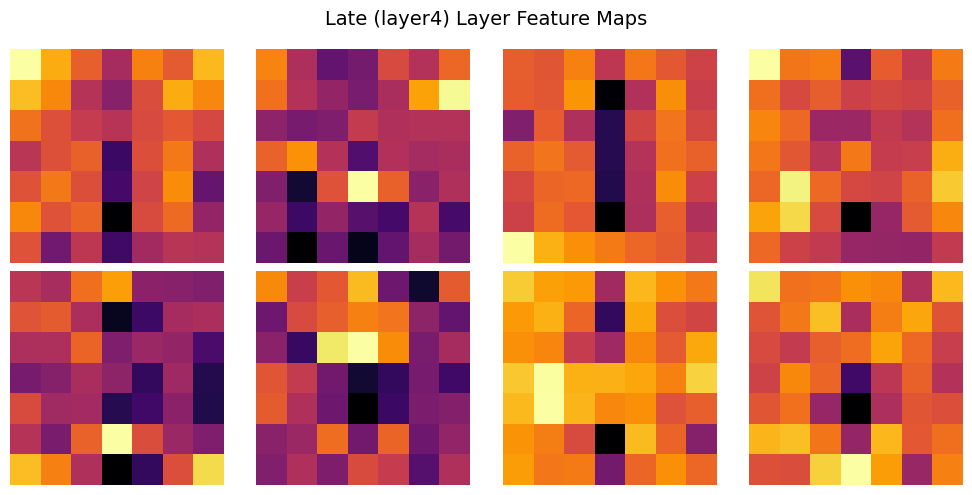

In [15]:
# Register hooks for early and late layers
activations = {}
def hook_fn(name):
    def hook(module, input, output):
        activations[name] = output.detach()
    return hook

# Register hooks to selected layers
early_layer = model.conv1
mid_layer = model.layer2[0].conv1
late_layer = model.layer4[0].conv1

handles = [
    early_layer.register_forward_hook(hook_fn('early')),
    mid_layer.register_forward_hook(hook_fn('mid')),
    late_layer.register_forward_hook(hook_fn('late'))
]

# Forward pass
with torch.no_grad():
    _ = model(input_tensor)  # Fixed the syntax error here

# Remove hooks
for handle in handles:
    handle.remove()

# Function to visualize feature maps with selective display
def visualize_feature_maps(feature_maps, layer_name, num_filters=8):
    # Create a grid of feature maps
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    axes = axes.flatten()
    
    # Use only a subset of channels for clarity
    if feature_maps.shape[1] > num_filters:
        # Select evenly spaced filters
        indices = np.linspace(0, feature_maps.shape[1]-1, num_filters, dtype=int)
        selected_maps = feature_maps[0, indices].cpu().numpy()
    else:
        selected_maps = feature_maps[0, :num_filters].cpu().numpy()
    
    # Plot each feature map
    for i, feature_map in enumerate(selected_maps):
        # Normalize for visualization
        feature_map = (feature_map - feature_map.min()) / (feature_map.max() - feature_map.min() + 1e-8)
        axes[i].imshow(feature_map, cmap='inferno')
        axes[i].axis('off')
    
    plt.suptitle(f"{layer_name} Layer Feature Maps", fontsize=14)
    plt.tight_layout()
    return fig

# Display original input
plt.figure(figsize=(5, 5))
plt.imshow(input_image)
plt.title("Input Image")
plt.axis('off')
plt.tight_layout()
plt.show()

# Visualize early, mid, and late feature maps
early_fig = visualize_feature_maps(activations['early'], "Early (conv1)")
plt.show()

mid_fig = visualize_feature_maps(activations['mid'], "Middle (layer2)")
plt.show()

late_fig = visualize_feature_maps(activations['late'], "Late (layer4)")
plt.show()

In [16]:
print(f'Final Train Accuracy: {train_accs[-1]} %')
print(f'Baseline Model Accuracy: {base_acc} %') 
torch.mps.empty_cache()
for x, y in test_loader:
    # Forward Pass Train
    input = x.to(mps_device)
    label = y.to(mps_device)
    # Forward Pass Val
    output = model(input)
    y_pred = torch.max(output, 1)[1]
    print(f'Test Accuracy:{100 * (y_pred == label).sum().item() / len(label)} %')
    

Final Train Accuracy: 99.83333333333333 %
Baseline Model Accuracy: 37.0 %
Test Accuracy:100.0 %


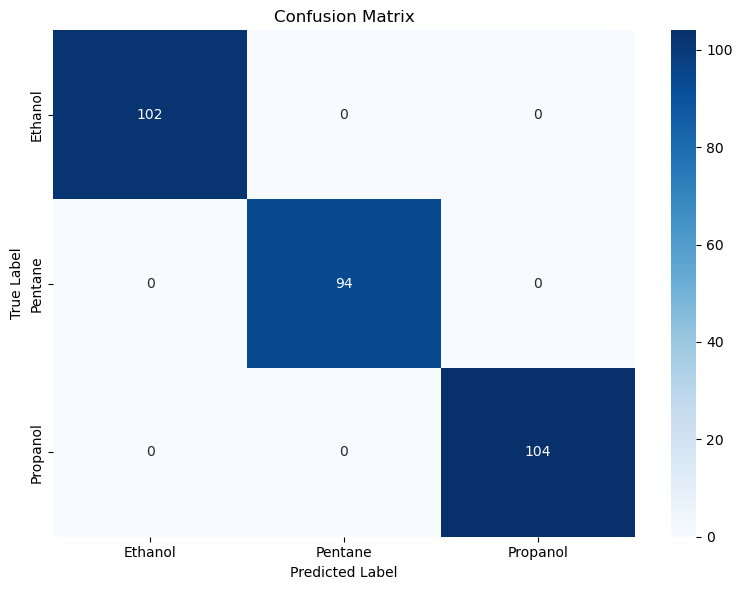

Macro-averaged metrics:
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000

Weighted-averaged metrics:
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000

Classification Report:
              precision    recall  f1-score   support

     Ethanol       1.00      1.00      1.00       102
     Pentane       1.00      1.00      1.00        94
    Propanol       1.00      1.00      1.00       104

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [17]:
label = label.cpu()
y_pred = y_pred.cpu()

cm = confusion_matrix(label, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
class_names = ['Ethanol', 'Pentane', 'Propanol']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()
    
precision_macro = precision_score(label, y_pred, average='macro')
recall_macro = recall_score(label, y_pred, average='macro')
f1_macro = f1_score(label, y_pred, average='macro')

precision_weighted = precision_score(label, y_pred, average='weighted')
recall_weighted = recall_score(label, y_pred, average='weighted')
f1_weighted = f1_score(label, y_pred, average='weighted')

print(f"Macro-averaged metrics:")
print(f"Precision: {precision_macro:.4f}")
print(f"Recall: {recall_macro:.4f}")
print(f"F1 Score: {f1_macro:.4f}")
print()
print(f"Weighted-averaged metrics:")
print(f"Precision: {precision_weighted:.4f}")
print(f"Recall: {recall_weighted:.4f}")
print(f"F1 Score: {f1_weighted:.4f}")
print()
print("Classification Report:")
print(classification_report(label, y_pred, target_names=class_names))

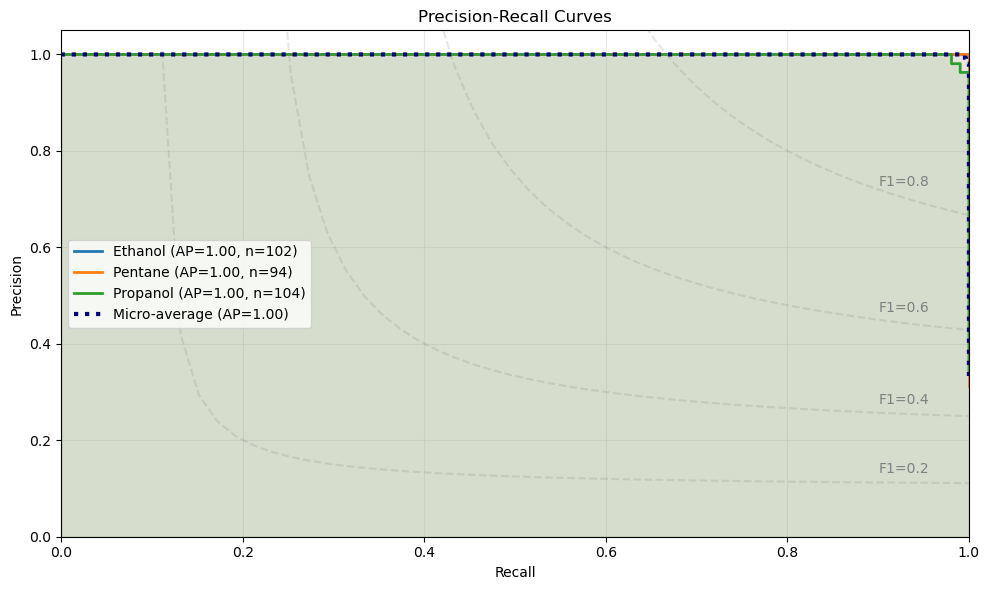

In [18]:
with torch.no_grad():
    y_true = label
    y_score = output.cpu().numpy()
    y_true_bin = F.one_hot(label, num_classes=len(class_names)).numpy()

model.eval()

# Compute PR curve and average precision for each class
precision = {}
recall = {}
avg_precision = {}

plt.figure(figsize=(10, 6))

class_names = ['Ethanol', 'Pentane', 'Propanol']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, (name, color) in enumerate(zip(class_names, colors)):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    avg_precision[i] = average_precision_score(y_true_bin[:, i], y_score[:, i])
    
    # Plot precision-recall curve
    plt.plot(recall[i], precision[i], color=color, lw=2, 
             label=f'{name} (AP={avg_precision[i]:.2f}, n={sum(y_true == i)})')
    
    # Add shaded area under curve
    plt.fill_between(recall[i], precision[i], alpha=0.1, color=color)

# Plot iso-f1 curves
f_scores = np.linspace(0.2, 0.8, num=4)
for f_score in f_scores:
    x = np.linspace(0.01, 1)
    y = f_score * x / (2 * x - f_score)
    plt.plot(x[y >= 0], y[y >= 0], color='gray', alpha=0.2, linestyle='--')
    plt.annotate(f'F1={f_score:0.1f}', xy=(0.9, y[45] + 0.02), color='gray')

# Calculate and plot the micro-average PR curve
precision_micro, recall_micro, _ = precision_recall_curve(y_true_bin.ravel(), y_score.ravel())
avg_precision_micro = average_precision_score(y_true_bin, y_score, average="micro")
plt.plot(recall_micro, precision_micro, color='navy', linestyle=':', linewidth=3,
         label=f'Micro-average (AP={avg_precision_micro:.2f})')

# Styling
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.tight_layout()
plt.show()



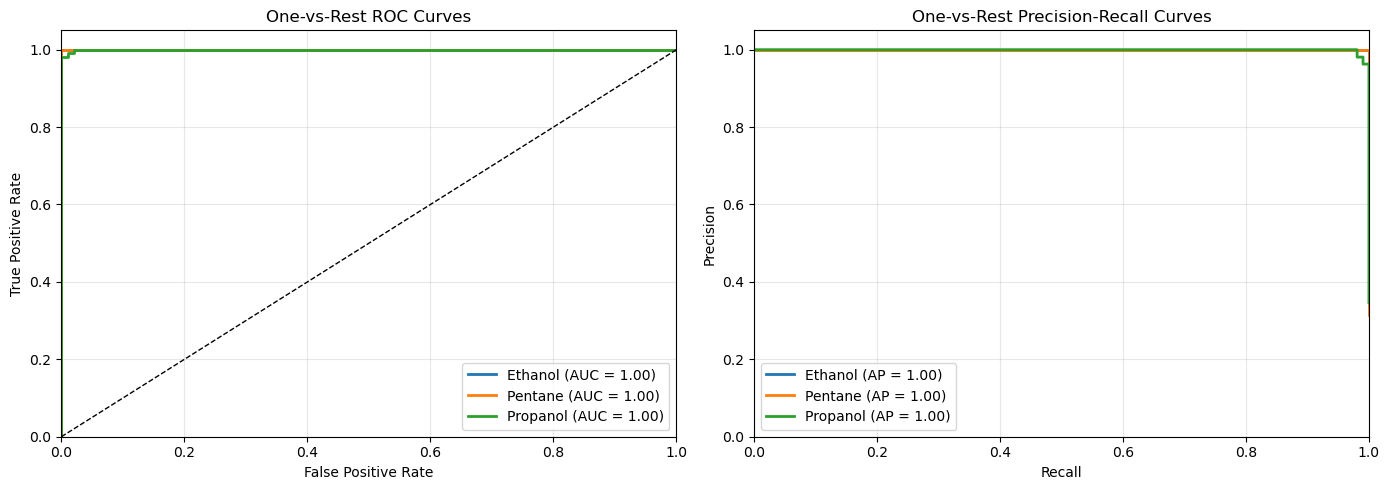

,Class,Accuracy,Precision,Recall,F1,Support
0,Ethanol,1.0,1.0,1.0,1.0,102
1,Pentane,1.0,1.0,1.0,1.0,94
2,Propanol,1.0,1.0,1.0,1.0,104


In [19]:
# Set up figure for ROC and PR curves in one-vs-rest setting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
class_names = ['Ethanol', 'Pentane', 'Propanol']

# Plot ROC curves
for i, (name, color) in enumerate(zip(class_names, colors)):
    # ROC curve
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    
    axes[0].plot(fpr, tpr, color=color, lw=2,
                label=f'{name} (AUC = {roc_auc:.2f})')
    
    # PR curve
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    axes[1].plot(recall, precision, color=color, lw=2,
                label=f'{name} (AP = {avg_precision[i]:.2f})')

# ROC curve styling
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('One-vs-Rest ROC Curves')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# PR curve styling
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('One-vs-Rest Precision-Recall Curves')
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Create binary classification metrics for each class
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

# Calculate metrics for each class using one-vs-rest approach
metrics_table = []

for i, name in enumerate(class_names):
    # Convert to binary problem
    y_true_binary = (y_true == i).int()
    y_pred_binary = (np.argmax(y_score, axis=1) == i).astype(int)
    
    # Calculate metrics
    accuracy = accuracy_score(y_true_binary, y_pred_binary)
    precision = precision_score(y_true_binary, y_pred_binary)
    recall = recall_score(y_true_binary, y_pred_binary)
    f1 = f1_score(y_true_binary, y_pred_binary)
    support = int(sum(y_true_binary))
    
    metrics_table.append([name, accuracy, precision, recall, f1, support])

# Create and display DataFrame
binary_metrics = pd.DataFrame(metrics_table, 
                             columns=['Class', 'Accuracy', 'Precision', 'Recall', 'F1', 'Support'])
binary_metrics.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1': '{:.4f}',
    'Support': '{:,}'
})
display(binary_metrics)

